<a href="https://colab.research.google.com/github/analicepinho/C-lculo-Num-rico/blob/main/Anima%C3%A7%C3%A3o_Elimina%C3%A7%C3%A3odeGauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Animação Eliminação de Gauss**

###**Analice Costa Pinho**  
Cálculo Numérico  
Prof Raquel J. Lobosco

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyBboxPatch

Definição da matriz:

In [31]:
A_inicial = np.array([
    [7.0,  15.0, -13.0],
    [8.0, -1.0,  35.0],
    [-2.0, 21.0,  2.0]
], dtype=float)

b_inicial = np.array([6.0, -5.0, -17.0], dtype=float)

Eliminação de Gauss

In [33]:
def algoritmo_gauss(A, b):
    M = np.column_stack([A, b]).astype(float)
    n = len(b)
    passos = []

    passos.append({
        'M': M.copy(),
        'titulo': "Sistema Inicial Expresso na Forma Matricial [A | b]",
        'detalhe': "Objetivo: Transformar a matriz A em uma Matriz Triangular Superior.",
        'linha_ativa': None,
        'pivo_pos': None,
        'formula': ""
    })

    for k in range(n - 1):
        pivo = M[k, k]

        for i in range(k + 1, n):
            fator = M[i, k] / pivo
            M[i, :] -= fator * M[k, :]

            passos.append({
                'M': M.copy(),
                'titulo': f"Eliminação do elemento L{i+1}C{k+1}",
                'detalhe': f"Multiplicador m = M[{i+1},{k+1}] / M[{k+1},{k+1}] = {fator:.2f}",
                'linha_ativa': i,
                'pivo_pos': (k, k),
                'formula': f"L{i+1} ← L{i+1} - ({fator:.2f}) × L{k+1}"
            })

    passos.append({
        'M': M.copy(),
        'titulo': "Forma Triangular Superior Concluída!",
        'detalhe': "Agora o sistema pode ser resolvido facilmente por Substituição Regressiva.",
        'linha_ativa': None,
        'pivo_pos': None,
        'formula': "Triangulação Concluída"
    })

    return passos

Animação da Eliminação de Gauss

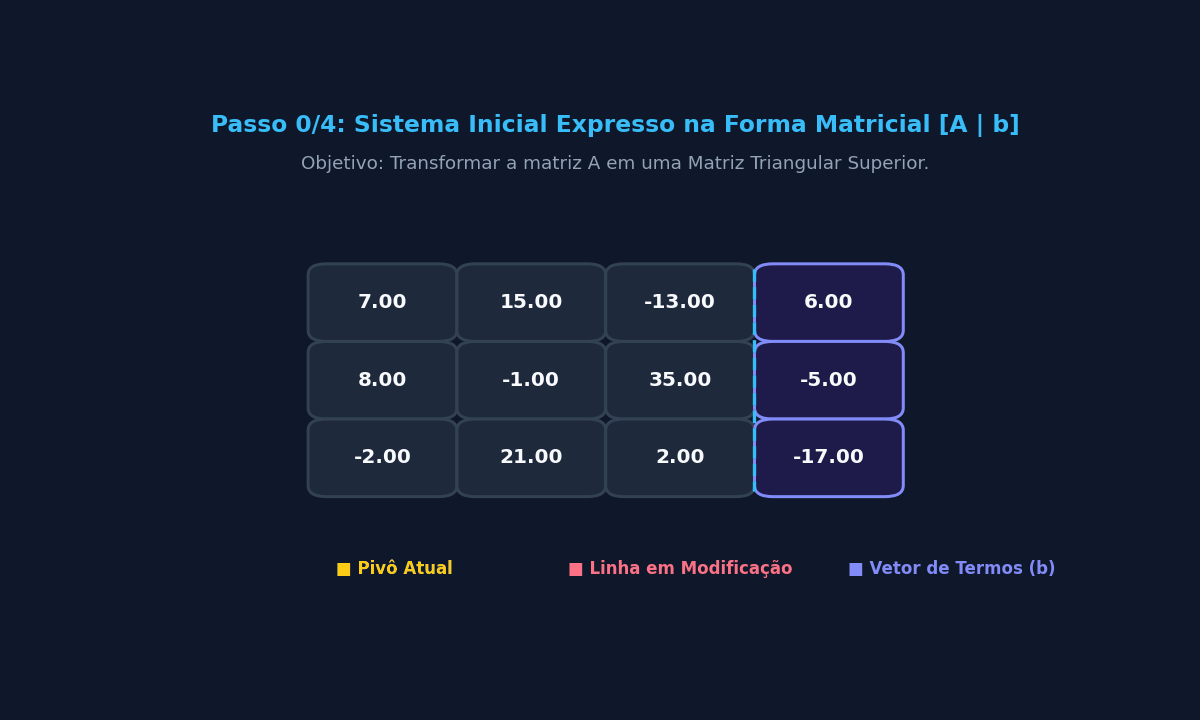

In [36]:
def criar_animacao(A, b, nome_gif="elimination_gauss.gif"):
    passos = algoritmo_gauss(A, b)

    fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
    fig.patch.set_facecolor('#0F172A')

    def atualizar_quadro(frame):
        ax.clear()
        ax.set_facecolor('#0F172A')
        ax.axis('off')

        step = passos[frame]
        M = step['M']
        n_lin, n_col = M.shape

        ax.text(0.5, 0.93, f"Passo {frame}/{len(passos)-1}: {step['titulo']}",
                ha='center', va='center', fontsize=14, fontweight='bold', color='#38BDF8',
                transform=ax.transAxes)

        ax.text(0.5, 0.86, step['detalhe'],
                ha='center', va='center', fontsize=11, color='#94A3B8',
                transform=ax.transAxes)

        if step['formula']:
            ax.text(0.5, 0.79, f"Operação:  {step['formula']}",
                    ha='center', va='center', fontsize=11, fontweight='bold',
                    color='#F43F5E', transform=ax.transAxes)

        x_start = 0.18
        y_start = 0.55
        dx = 0.16
        dy = 0.14

        for i in range(n_lin):
            for j in range(n_col):
                x = x_start + j * dx
                y = y_start - i * dy
                val = M[i, j]

                bg_color = '#1E293B'
                border_color = '#334155'
                text_color = '#F8FAFC'

                if step['pivo_pos'] == (i, j):
                    bg_color = '#854D0E'
                    border_color = '#FACC15'
                    text_color = '#FEF08A'
                elif step['linha_ativa'] == i:
                    bg_color = '#881337'
                    border_color = '#FB7185'
                    text_color = '#FFE4E6'
                elif j == n_col - 1:
                    bg_color = '#1E1B4B'
                    border_color = '#818CF8'

                card = FancyBboxPatch((x, y), dx - 0.02, dy - 0.02,
                                      boxstyle="round,pad=0.01,rounding_size=0.02",
                                      facecolor=bg_color, edgecolor=border_color, lw=1.8,
                                      transform=ax.transAxes)
                ax.add_patch(card)

                texto = f"{val:.2f}" if abs(val) > 1e-10 else "0.00"
                ax.text(x + (dx - 0.02) / 2, y + (dy - 0.02) / 2, texto,
                        ha='center', va='center', fontsize=12, fontweight='bold',
                        color=text_color, transform=ax.transAxes)

        x_div = x_start + 3 * dx - 0.01
        ax.plot([x_div, x_div], [y_start + dy - 0.02, y_start - 2 * dy],
                color='#38BDF8', linestyle='--', linewidth=2, transform=ax.transAxes)

        ax.text(0.2, 0.12, "■ Pivô Atual", color='#FACC15', fontsize=10, fontweight='bold', transform=ax.transAxes)
        ax.text(0.45, 0.12, "■ Linha em Modificação", color='#FB7185', fontsize=10, fontweight='bold', transform=ax.transAxes)
        ax.text(0.75, 0.12, "■ Vetor de Termos (b)", color='#818CF8', fontsize=10, fontweight='bold', transform=ax.transAxes)

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

    ani = animation.FuncAnimation(fig, atualizar_quadro, frames=len(passos), interval=1800, repeat=True)
    ani.save(nome_gif, writer='pillow', fps=0.6)
    plt.close()

criar_animacao(A_inicial, b_inicial, "elimination_gauss.gif")

from IPython.display import Image, display

criar_animacao(A_inicial, b_inicial, "elimination_gauss.gif")
display(Image(filename="elimination_gauss.gif"))